# Лабораторная работа 2

**Тема:** персональные рекомендации новых товаров по истории покупок.

Сравниваю MostPop, ItemKNN и EASE на покупках UCI Online Retail. Основная метрика — NDCG@10.

## 1. Постановка задачи и источник данных

Планирую рекомендовать покупателю до 10 товаров, которые он ещё не покупал. Положительный сигнал — покупка товара в будущем окне. Повторную покупку уже известного товара исключаю из целевой релевантности.

Использую датасет [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) — набор записей о покупках в британском интернет-магазине подарков с 1 декабря 2010 года по 9 декабря 2011 года. Каждая строка содержит один товар из заказа, его количество и цену, дату покупки и идентификатор покупателя. По этим данным восстанавливаю историю покупок и формирую рекомендации новых товаров.

Для обучения задаю бинарную пару «покупатель — товар» независимо от количества и повторных заказов: большой оптовый заказ не должен автоматически означать большее предпочтение.

Фиксирую seed и окружение.

In [1]:
from pathlib import Path
import os
for name in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','VECLIB_MAXIMUM_THREADS']:
    os.environ[name]='2'
ROOT = Path.cwd() if Path.cwd().name == 'lab-2' else Path.cwd() / 'lab-2'
DATA = ROOT / 'data'
RAW, FIGURES = DATA / 'raw', DATA / 'figures'
for folder in [RAW, FIGURES, DATA / '.mplconfig']:
    folder.mkdir(parents=True, exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(DATA / '.mplconfig')
import json, hashlib, zipfile, subprocess, platform, sys, time
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import scipy
from scipy import sparse, linalg
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits, threadpool_info
from IPython.display import display, Markdown
SEED = 42
np.random.seed(SEED)
blas_limit = threadpool_limits(limits=2)
BLUE, ORANGE, GREEN = '#3978a8', '#db9140', '#559883'
plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.dpi':110,
                     'axes.spines.top':False, 'axes.spines.right':False})
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_colwidth', 65)
versions = {name:version(name) for name in ['numpy','pandas','scipy','matplotlib','openpyxl','nbformat','nbclient','ipykernel','threadpoolctl']}
environment = {'python':sys.version, 'platform':platform.platform(), 'cpu_count':os.cpu_count(),
               'versions':versions, 'seed':SEED, 'blas':threadpool_info()}
(DATA / 'environment.json').write_text(json.dumps(environment, ensure_ascii=False, indent=2))
print(platform.platform(), '| CPU:', os.cpu_count(), '| BLAS: 2 потока')
display(pd.Series(versions, name='Версия').to_frame())
def save_table(frame, name):
    frame.to_csv(DATA / (name + '.csv'), index=False)
    return frame

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

macOS-26.6.2-arm64-arm-64bit-Mach-O | CPU: 10 | BLAS: 2 потока


,Версия
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
matplotlib,3.11.2
openpyxl,3.1.5
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0
threadpoolctl,3.6.0


In [2]:
URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
archive = RAW / 'online-retail.zip'
manifest_path = RAW / 'source.json'
if not archive.exists():
    temporary = archive.with_suffix('.download')
    subprocess.run(['curl','--fail','--location','--connect-timeout','20','--max-time','180',
                    '--retry','2',URL,'--output',str(temporary)], check=True)
    with zipfile.ZipFile(temporary) as z:
        assert z.testzip() is None
    temporary.replace(archive)
sha = digest(archive)
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
if manifest.get('sha256') != sha:
    manifest = {'url':URL, 'description_url':'https://archive.ics.uci.edu/dataset/352/online+retail',
                'author':'Daqing Chen (2015)', 'doi':'10.24432/C5BW33', 'license':'CC BY 4.0',
                'retrieved_at':datetime.now(timezone.utc).isoformat(), 'sha256':sha,
                'bytes':archive.stat().st_size, 'download':'curl, timeout=180s, retry=2'}
    manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
(DATA/'source_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
cache, cache_key = RAW / 'source-table.pkl', RAW / 'source-table.sha256'
if cache.exists() and cache_key.exists() and cache_key.read_text() == sha:
    raw = pd.read_pickle(cache)
else:
    with zipfile.ZipFile(archive) as z:
        assert z.testzip() is None
        with z.open('Online Retail.xlsx') as f:
            raw = pd.read_excel(f, engine='openpyxl')
    raw.to_pickle(cache)
    cache_key.write_text(sha)
print('SHA-256:', sha)
print('Строк и полей:', raw.shape)
display(raw.head())

SHA-256: f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b
Строк и полей: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Качество данных и EDA

Сначала проверяю все исходные строки, включая анонимные покупки и отмены. Описание источника не заменяет фактическую проверку пропусков. Полные совпадения всех восьми полей считаю возможными техническими дублями и оставляю одно вхождение. Без ID строки счёта это допущение нельзя доказать. Повторные пары в других счетах сохраняю.

Для целевой истории оставляю идентифицируемые покупки с положительными количеством и ценой. Служебные StockCode без пяти начальных цифр (доставка, комиссии и корректировки) исключаю по заранее заданному правилу `\d{5}[A-Za-z]*`. Названия очищаю только от крайних пробелов, отсутствие названия не мешает учесть покупку. Активных покупателей и популярные товары по статистическому порогу не удаляю.

In [3]:
schema = pd.DataFrame({'field':raw.columns, 'dtype':raw.dtypes.astype(str).values,
                       'missing':raw.isna().sum().values})
display(save_table(schema, 'raw_schema'))
df = raw.copy()
for col in ['InvoiceNo','StockCode']:
    df[col] = df[col].astype('string').str.strip()
df['InvoiceDate'] = pd.to_datetime(df.InvoiceDate, errors='coerce')
df['Description'] = df.Description.astype('string').str.strip()
checks = {
 'Точные дубли всех полей':raw.duplicated().sum(),
 'Пустая дата':df.InvoiceDate.isna().sum(),
 'Дата вне периода источника':(~df.InvoiceDate.between('2010-12-01','2011-12-10', inclusive='left') & df.InvoiceDate.notna()).sum(),
 'Отмена C':df.InvoiceNo.str.upper().str.startswith('C').sum(),
 'Количество <= 0':(df.Quantity <= 0).sum(),
 'Цена <= 0':(df.UnitPrice <= 0).sum(),
 'Необычный код товара':(~df.StockCode.str.fullmatch(r'\d{5}[A-Za-z]*', na=False)).sum(),
 'Некорректный CustomerID':(df.CustomerID.notna() & ((df.CustomerID <= 0) | (df.CustomerID % 1 != 0))).sum(),
 'Нечисловая цена/количество':(~np.isfinite(df.UnitPrice) | ~np.isfinite(df.Quantity)).sum(),
 'Необычный номер счёта':(~df.InvoiceNo.str.fullmatch(r'C?\d{6}', na=False)).sum(),
}
display(save_table(pd.Series(checks, name='rows').rename_axis('check').reset_index(), 'quality_checks'))
quality=[]
def remove(mask, reason, decision):
    global df
    before=len(df)
    df=df.loc[~mask].copy()
    quality.append({'problem':reason,'removed':before-len(df),'remaining':len(df),'decision':decision})
remove(df.duplicated(), 'Совпадение всех полей', 'Оставляю первую строку. Предположение о техническом дубле')
remove(df.CustomerID.isna() | (df.CustomerID <= 0) | (df.CustomerID % 1 != 0), 'Нет корректного покупателя', 'Исключаю из персонализации')
remove(df.InvoiceDate.isna() | ~df.InvoiceDate.between('2010-12-01','2011-12-10',inclusive='left'), 'Некорректная дата', 'Исключаю')
remove(df.InvoiceNo.isna() | df.InvoiceNo.str.upper().str.startswith('C') | (df.Quantity<=0), 'Отмена или неположительное количество', 'Не считаю положительным сигналом')
remove(~np.isfinite(df.UnitPrice) | (df.UnitPrice<=0) | ~np.isfinite(df.Quantity), 'Неположительная цена/некорректное число', 'Исключаю бесплатные и некорректные позиции')
remove(~df.StockCode.str.fullmatch(r'\d{5}[A-Za-z]*',na=False), 'Служебный код', 'Оставляю товарные коды')
df['CustomerID']=df.CustomerID.astype(int)
df=df.sort_values(['InvoiceDate','InvoiceNo','CustomerID','StockCode'], kind='stable').reset_index(drop=True)
display(save_table(pd.DataFrame(quality), 'quality_report'))
save_table(df, 'clean_events')
assert df.CustomerID.notna().all() and df.StockCode.notna().all()
print('Период исходных данных:', raw.InvoiceDate.min(), '—', raw.InvoiceDate.max())
print('Типы событий в исходных строках:', {'отмена':int(raw.InvoiceNo.astype(str).str.upper().str.startswith('C').sum()),
      'остальные':int((~raw.InvoiceNo.astype(str).str.upper().str.startswith('C')).sum())})
print('Нет отдельной таблицы товаров: связь StockCode–Description находится в строках покупок.')

,field,dtype,missing
0,InvoiceNo,object,0
1,StockCode,object,0
2,Description,object,1454
3,Quantity,int64,0
4,InvoiceDate,datetime64[us],0
5,UnitPrice,float64,0
6,CustomerID,float64,135080
7,Country,str,0


,check,rows
0,Точные дубли всех полей,5268
1,Пустая дата,0
2,Дата вне периода источника,0
3,Отмена C,9288
4,Количество <= 0,10624
5,Цена <= 0,2517
6,Необычный код товара,2995
7,Некорректный CustomerID,0
8,Нечисловая цена/количество,0
9,Необычный номер счёта,3


,problem,removed,remaining,decision
0,Совпадение всех полей,5268,536641,Оставляю первую строку. Предположение о техническом дубле
1,Нет корректного покупателя,135037,401604,Исключаю из персонализации
2,Некорректная дата,0,401604,Исключаю
3,Отмена или неположительное количество,8872,392732,Не считаю положительным сигналом
4,Неположительная цена/некорректное число,40,392692,Исключаю бесплатные и некорректные позиции
5,Служебный код,1542,391150,Оставляю товарные коды


Период исходных данных: 2010-12-01 08:26:00 — 2011-12-09 12:50:00
Типы событий в исходных строках: {'отмена': 9288, 'остальные': 532621}
Нет отдельной таблицы товаров: связь StockCode–Description находится в строках покупок.


,value
events,391150.000000
users,4334.000000
items,3659.000000
pairs,266221.000000
density,0.016788
repeat_pair_rows,124929.000000
multiple_names,210.000000
missing_names,0.000000
top1pct_event_share,0.097947
single_user_items,178.000000


,events,items,orders
count,4334.0,4334.0,4334.0
mean,90.3,61.4,4.2
std,224.7,85.3,7.6
min,1.0,1.0,1.0
50%,41.0,35.0,2.0
90%,202.0,142.7,9.0
99%,655.0,353.7,30.0
max,7667.0,1785.0,206.0


,events,users
count,3659.0,3659.0
mean,106.9,72.8
std,161.1,91.6
min,1.0,1.0
50%,48.0,40.0
90%,278.2,186.0
99%,794.7,414.4
max,2023.0,881.0


Наиболее активные покупатели:


,events,items,orders
CustomerID,,,
17841,7667,1322,124
14911,5584,1785,198
14096,5095,1118,17
12748,4397,1766,206
14606,2674,816,90


Крупнейшие количества:


,CustomerID,StockCode,Description,Quantity,InvoiceDate
390689,16446,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00
36375,12346,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00
303441,12901,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00
140979,13135,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00
60437,18087,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00


Коды с несколькими названиями: {'16156L': 2, '17107D': 3, '20622': 2, '20725': 2, '20914': 2}


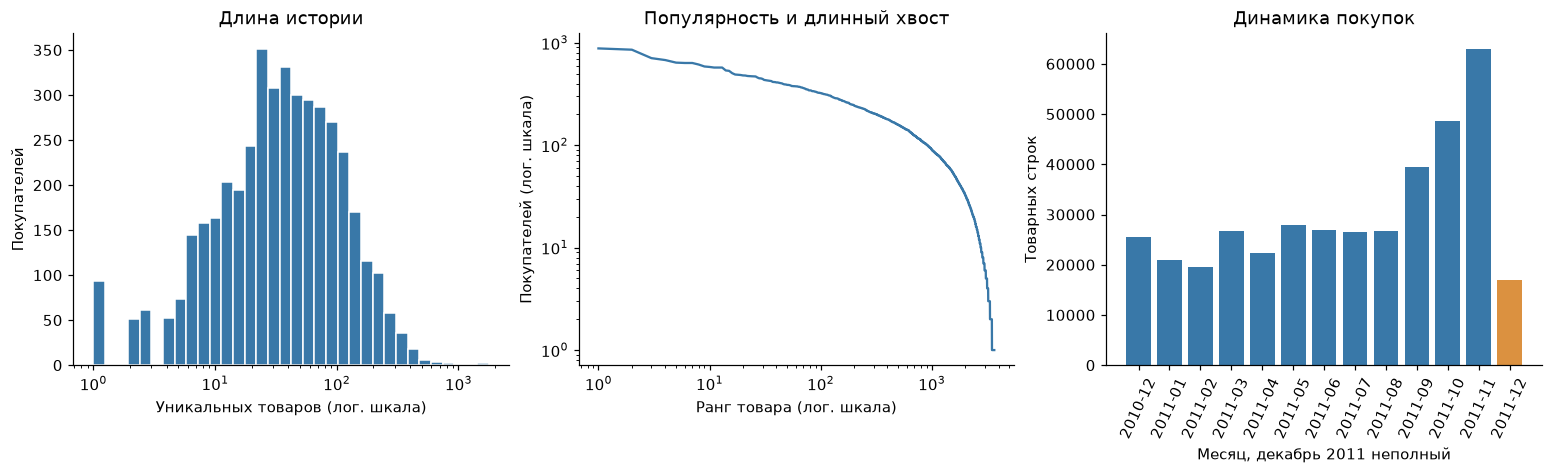

In [4]:
pairs = df[['CustomerID','StockCode']].drop_duplicates()
user_activity = df.groupby('CustomerID').agg(events=('StockCode','size'), items=('StockCode','nunique'), orders=('InvoiceNo','nunique'))
item_activity = df.groupby('StockCode').agg(events=('CustomerID','size'), users=('CustomerID','nunique'))
U,I = len(user_activity),len(item_activity)
density = len(pairs)/(U*I)
name_counts = df.groupby('StockCode').Description.nunique()
summary = {'events':len(df),'users':U,'items':I,'pairs':len(pairs),'density':density,
           'repeat_pair_rows':len(df)-len(pairs), 'multiple_names':int((name_counts>1).sum()),
           'missing_names':int(df.Description.isna().sum()),
           'top1pct_event_share':float(item_activity.events.nlargest(max(1,int(np.ceil(I*.01)))).sum()/len(df)),
           'single_user_items':int((item_activity.users==1).sum())}
(DATA/'eda_summary.json').write_text(json.dumps(summary,indent=2))
display(pd.Series(summary, name='value').to_frame())
display(user_activity.describe(percentiles=[.5,.9,.99]).round(1))
display(item_activity.describe(percentiles=[.5,.9,.99]).round(1))
print('Наиболее активные покупатели:');display(user_activity.nlargest(5,'events'))
print('Крупнейшие количества:');display(df.nlargest(5,'Quantity')[['CustomerID','StockCode','Description','Quantity','InvoiceDate']])
print('Коды с несколькими названиями:', name_counts[name_counts>1].head(5).to_dict())
save_table(user_activity.reset_index(),'user_activity')
save_table(item_activity.reset_index(),'item_activity')
fig,axes=plt.subplots(1,3,figsize=(14,4.2),layout='constrained')
axes[0].hist(user_activity['items'], bins=np.geomspace(1,user_activity['items'].max()+1,35),color=BLUE,edgecolor='white')
axes[0].set(xscale='log',xlabel='Уникальных товаров (лог. шкала)',ylabel='Покупателей',title='Длина истории')
ranked=item_activity.users.sort_values(ascending=False).to_numpy()
axes[1].loglog(np.arange(1,I+1),ranked,color=BLUE)
axes[1].set(xlabel='Ранг товара (лог. шкала)',ylabel='Покупателей (лог. шкала)',title='Популярность и длинный хвост')
monthly=df.groupby(df.InvoiceDate.dt.to_period('M')).size()
axes[2].bar(monthly.index.astype(str),monthly.values,color=[BLUE]*(len(monthly)-1)+[ORANGE])
axes[2].tick_params(axis='x',rotation=65)
axes[2].set(ylabel='Товарных строк',title='Динамика покупок',xlabel='Месяц, декабрь 2011 неполный')
fig.savefig(FIGURES/'eda.png',dpi=160,bbox_inches='tight');plt.show()

Плотность рассчитал как $|\{(u,i):x_{ui}>0\}|/(|U|\cdot|I|)$, разреженность — $1-\text{density}$. Повторные строки пары не увеличивают заполненность. Количество покупок и уникальных товаров показал отдельно: оптовые количества и повторные заказы могут сильно отличаться от длины бинарной истории.

### Наблюдения по данным

В исходных данных нашёл пропуски идентификаторов покупателей, полные дубли, отмены и служебные позиции. После очистки осталось около 391 тысячи записей о покупках, 4,3 тысячи покупателей и 3,7 тысячи товаров. Подробные причины и объёмы исключений привёл в таблице качества данных.

Матрица взаимодействий оказалась разреженной на 98,3%. Повторные покупки сохранил в истории, но при обучении учитывал каждую пару «покупатель — товар» один раз. Так частые заказы и большие количества не получали дополнительного веса.

Истории покупателей заметно различались по длине. У половины было не больше 35 разных товаров, а у отдельных покупателей — больше тысячи. Очень крупные заказы не удалял только из-за их размера, поскольку среди клиентов есть оптовики. При этом отмены не сопоставлял с предыдущими покупками, поэтому положительная запись не всегда означает окончательную продажу.

Популярность товаров тоже оказалась неравномерной. Одни встречались у сотен покупателей, другие — только у одного. Поэтому включил MostPop как базовый метод для сравнения с персональными рекомендациями. На графике также заметил рост активности в октябре–ноябре. Возможная причина — приближение сезона подарков, но отдельно эту гипотезу не проверял.

После очистки названия были заполнены у всех товаров, хотя у некоторых кодов встречались разные варианты текста. Идентификатором оставил StockCode. Названия позволяют понять содержание рекомендаций, но данных об остатках и показах нет, поэтому фактическую доступность товаров оценить нельзя.

## 3. Подготовка и разделение выборок

Разделяю покупки по времени. На данных до октября обучаю модели, на октябре выбираю параметры, а на ноябре и начале декабря сравниваю итоговое качество. Так проверяю, насколько история покупок помогает предсказать следующие покупки. Тестовое окно длиннее октября и приходится на сезон подарков, поэтому объёмы этих частей напрямую не сравниваю.

После настройки переобучаю все методы на данных до ноября. Популярность, связи между товарами и названия для примеров получаю только из доступной на этот момент истории. Будущие покупки в обучение не включаю. Использую все данные после очистки, без отбора покупателей по будущей активности.

Рекомендую товары из обучающего каталога, которые покупатель ещё не приобретал. Основное качество считаю для известных покупателей с хотя бы одной новой покупкой из этого каталога. Отдельно проверяю новых покупателей и покупки товаров, которых модель ещё не знает. Случаи без подходящих будущих покупок учитываю в таблице ниже, но не включаю в средние метрики.

In [5]:
VAL_START=pd.Timestamp('2011-10-01')
TEST_START=pd.Timestamp('2011-11-01')
train=df[df.InvoiceDate<VAL_START].copy()
validation=df[(df.InvoiceDate>=VAL_START)&(df.InvoiceDate<TEST_START)].copy()
test=df[df.InvoiceDate>=TEST_START].copy()
final_train=df[df.InvoiceDate<TEST_START].copy()
assert train.InvoiceDate.max()<validation.InvoiceDate.min()
assert validation.InvoiceDate.max()<test.InvoiceDate.min()
split_rows=[]
for name, part, history in [('train',train,train),('validation',validation,train),('test',test,final_train)]:
    split_rows.append({'split':name,'start':part.InvoiceDate.min(),'end':part.InvoiceDate.max(),
                       'events':len(part),'users':part.CustomerID.nunique(),'items':part.StockCode.nunique(),
                       'unseen_users':len(set(part.CustomerID)-set(history.CustomerID)),
                       'unseen_items':len(set(part.StockCode)-set(history.StockCode))})
    save_table(part, name+'_events')
display(save_table(pd.DataFrame(split_rows),'split_summary'))
def histories(frame):
    return frame.groupby('CustomerID').StockCode.agg(set).to_dict()

def targets(history, future):
    seen=histories(history); catalog=set(history.StockCode)
    all_new={u:items-seen.get(u,set()) for u,items in histories(future).items()}
    eligible={u:items&catalog for u,items in all_new.items()}
    warm={u:r for u,r in eligible.items() if u in seen and r}
    warm_all={u:r for u,r in all_new.items() if u in seen and r}
    cold={u:r for u,r in eligible.items() if u not in seen and r}
    audit={'future_users':len(all_new),'future_events':len(future),
           'future_unique_pairs':len(future[['CustomerID','StockCode']].drop_duplicates()),
           'repeat_pairs_excluded':sum(len(v & seen.get(u,set())) for u,v in histories(future).items()),
           'unseen_item_pairs':sum(len(v-catalog) for v in all_new.values()),
           'warm_eligible_users':len(warm), 'warm_users_with_new_including_unseen':len(warm_all),
           'cold_users':sum(u not in seen for u in all_new), 'cold_eligible_users':len(cold),
           'users_without_new_items':sum(not v for v in all_new.values()),
           'users_with_new_but_no_available_items':sum(bool(all_new[u]) and not v for u,v in eligible.items()),
           'repeat_event_rows_excluded':sum(i in seen.get(u,set()) for u,i in zip(future.CustomerID,future.StockCode))}
    return warm,warm_all,cold,audit
val_truth,_,_,va=targets(train,validation)
test_truth,test_all_truth,cold_truth,ta=targets(final_train,test)
audit=pd.DataFrame([{'split':'validation',**va},{'split':'test',**ta}])
display(save_table(audit,'evaluation_population'))
config={'seed':SEED,'validation_start':str(VAL_START),'test_start':str(TEST_START),
        'feedback':'binary unique purchases','candidate_policy':'history catalog minus seen',
        'primary_metric':'NDCG@10','K':[5,10,20], 'selection':'full cleaned data, no sampling',
        'source_sha256':sha, 'refit':'train+validation for all models',
        'cleaning':{'drop_exact_duplicates':True,'quantity_min_exclusive':0,'price_min_exclusive':0,
                    'stockcode_regex':r'\d{5}[A-Za-z]*','drop_missing_customer':True},
        'search':{'ItemKNN_neighbors':[30,100],'ItemKNN_shrink':10,'EASE_lambda':[100,1000]}}
(DATA/'protocol.json').write_text(json.dumps(config,ensure_ascii=False,indent=2))

,split,start,end,events,users,items,unseen_users,unseen_items
0,train,2010-12-01 08:26:00,2011-09-30 15:52:00,262637,3613,3502,0,0
1,validation,2011-10-02 10:32:00,2011-10-31 17:13:00,48611,1361,2617,357,105
2,test,2011-11-01 08:16:00,2011-12-09 12:50:00,79902,1904,2766,364,52


,split,future_users,future_events,future_unique_pairs,repeat_pairs_excluded,unseen_item_pairs,warm_eligible_users,warm_users_with_new_including_unseen,cold_users,cold_eligible_users,users_without_new_items,users_with_new_but_no_available_items,repeat_event_rows_excluded
0,validation,1361,48611,44190,11709,1793,937,944,357,356,60,8,14169
1,test,1904,79902,67524,22183,733,1440,1449,364,364,91,9,30146


785

### Охват разбиения

Для настройки получил 937 известных покупателей, для основного теста — 1 440. Подробные размеры и периоды выборок привёл в таблицах выше.

При подготовке оценки исключил уже купленные товары, поскольку задача — предложить новые. Некоторые будущие покупки оказались вне обучающего каталога.

В тесте также появились 364 новых покупателя. Для них предусмотрел рекомендации популярных товаров, поскольку персональной истории ещё нет.

Такое разбиение позволило проверить рекомендации на будущих покупках, но не устранило сезонный сдвиг между октябрём и предпраздничным периодом.

## 4. Методы рекомендаций

Представляю историю бинарной разреженной матрицей $X$: строки — покупатели, столбцы — товары. Единица означает, что покупатель хотя бы раз купил товар.

**MostPop** предлагает товары с наибольшим числом разных покупателей. Этот же метод использую для новых пользователей, у которых ещё нет истории.

**ItemKNN** ищет товары, которые покупают одни и те же люди. Сходство считаю по косинусу столбцов $X$ и умножаю на $n_{ij}/(n_{ij}+10)$, где $n_{ij}$ — число общих покупателей. Эта поправка ослабляет случайные совпадения редких товаров. Для каждого товара оставляю L ближайших соседей, а оценку кандидата получаю суммированием сходств с товарами истории: $X_uS$. Сходство товара с самим собой обнуляю. Проверяю 30 и 100 соседей.

**[EASE](https://arxiv.org/abs/1905.03375)** учится восстанавливать покупки по остальной истории пользователя. Подбираю веса $B$, минимизируя $\|X-XB\|_F^2+\lambda\|B\|_F^2$ при нулевой диагонали. Решение получаю через $P=(X^TX+\lambda I)^{-1}$ и $B_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$. Итоговые оценки — $X_uB$. Параметр λ ограничивает величину весов, проверяю значения 100 и 1000.

Выбираю EASE вместо ALS, поскольку размер каталога позволяет решить систему через Cholesky на доступной машине. Перед обучением оцениваю память для плотных матриц товар–товар и учитываю кубическую стоимость решения. Полную плотную матрицу покупатель–товар не создаю.

Все методы исключают уже купленные товары. При равных оценках сортирую по StockCode. Нулевые и отрицательные оценки сохраняю в обычном порядке, поэтому список может включать слабые совпадения. Оценки разных моделей не считаю одинаково откалиброванными вероятностями.

In [6]:
class Recommender:
    def __init__(self, history, method='MostPop', parameter=None, shrink=10):
        start=time.perf_counter()
        self.method,self.parameter=method,parameter
        self.users=np.array(sorted(history.CustomerID.unique()))
        self.items=np.array(sorted(history.StockCode.unique()),dtype=str)
        self.uid={u:i for i,u in enumerate(self.users)}
        self.iid={i:j for j,i in enumerate(self.items)}
        pairs=history[['CustomerID','StockCode']].drop_duplicates()
        self.X=sparse.csr_matrix((np.ones(len(pairs)),(pairs.CustomerID.map(self.uid),pairs.StockCode.map(self.iid))),
                                 shape=(len(self.users),len(self.items)))
        self.pop=np.asarray(self.X.sum(axis=0)).ravel()
        self.W=None
        n=len(self.items)
        if method=='ItemKNN':
            gram=(self.X.T@self.X).tocsr()
            norm=np.sqrt(self.pop)
            coo=gram.tocoo()
            coo.data=coo.data/(norm[coo.row]*norm[coo.col])*coo.data/(coo.data+shrink)
            sim=coo.tocsr();sim.setdiag(0);sim.eliminate_zeros()
            rows,cols,values=[],[],[]
            for i in range(n):
                row=sim.getrow(i)
                order=np.lexsort((row.indices,-row.data))[:parameter]
                rows.extend([i]*len(order));cols.extend(row.indices[order]);values.extend(row.data[order])
            self.W=sparse.csr_matrix((values,(rows,cols)),shape=(n,n))
        elif method=='EASE':
            assert 5*n*n*8 < 1.5*1024**3, 'Плотная система превышает бюджет памяти'
            gram=(self.X.T@self.X).toarray()
            gram.flat[::n+1]+=parameter
            inv=linalg.cho_solve(linalg.cho_factor(gram,check_finite=False),np.eye(n),check_finite=False)
            self.W=np.ascontiguousarray(-inv/np.diag(inv)[None,:])
            np.fill_diagonal(self.W,0)
            assert np.isfinite(self.W).all()
        elif method!='MostPop':
            raise ValueError(method)
        self.fit_seconds=time.perf_counter()-start

    def recommend(self,user_id,k=10):
        if not isinstance(k,int) or isinstance(k,bool) or k<1:
            raise ValueError('k должен быть положительным целым числом')
        u=self.uid.get(user_id)
        if u is None or self.W is None:
            scores=self.pop.astype(float).copy()
        else:
            product=self.X.getrow(u)@self.W
            scores=product.toarray().ravel() if sparse.issparse(product) else np.asarray(product).ravel()
        if u is not None:
            scores[self.X.getrow(u).indices]=-np.inf
        valid=np.flatnonzero(np.isfinite(scores))
        order=valid[np.lexsort((valid,-scores[valid]))[:k]]
        return [(str(self.items[j]),float(scores[j])) for j in order]

n=train.StockCode.nunique()
print(f'Каталог train: {n}. Одна плотная item-item: {n*n*8/1024**2:.1f} МиБ. Бюджет пяти: {5*n*n*8/1024**2:.1f} МиБ')
# На игрушечной истории пользователь 1 покупает A,B; остаётся только C.
toy=pd.DataFrame({'CustomerID':[1,1,2,2,3], 'StockCode':['A','B','B','C','C']})
for method,param in [('MostPop',None),('ItemKNN',2),('EASE',10)]:
    m=Recommender(toy,method,param)
    assert m.X.shape==(3,3) and m.X[m.uid[1],m.iid['A']]==1
    assert [i for i,s in m.recommend(1,10)]==['C']
    assert len(m.recommend(-1,10))==3
    assert m.recommend(-1,10)==m.recommend(-1,10)
    if method=='ItemKNN':
        expected=(1/np.sqrt(2*2))*(1/11)
        assert np.isclose(m.W[m.iid['B'],m.iid['C']],expected)
    if method=='EASE':
        g=(m.X.T@m.X).toarray()+10*np.eye(3)
        assert np.allclose(g@m.W-np.diag(np.diag(g@m.W)),
                           (m.X.T@m.X).toarray()-np.diag(np.diag((m.X.T@m.X).toarray())))
    print(method,m.recommend(1,10),'| новый пользователь:',m.recommend(-1,10))
assert Recommender(toy).recommend(3,3)==[('B',2.0),('A',1.0)]
assert Recommender(toy[toy.CustomerID==1]).recommend(1,10)==[]
print('Ориентация, короткий и пустой список, фильтрация и равные scores проверены.')

Каталог train: 3502. Одна плотная item-item: 93.6 МиБ. Бюджет пяти: 467.8 МиБ
MostPop [('C', 2.0)] | новый пользователь: [('B', 2.0), ('C', 2.0), ('A', 1.0)]
ItemKNN [('C', 0.04545454545454544)] | новый пользователь: [('B', 2.0), ('C', 2.0), ('A', 1.0)]
EASE [('C', 0.07633587786259541)] | новый пользователь: [('B', 2.0), ('C', 2.0), ('A', 1.0)]
Ориентация, короткий и пустой список, фильтрация и равные scores проверены.


## 5. Метрики и протокол оценки

Проверяю не только попадания в будущие покупки, но и их положение в списке, новизну и охват каталога. Пусть $R_u$ — новые релевантные товары покупателя, $L_u^K$ — первые K рекомендаций, а $h_r$ — признак попадания на позиции r.

- **Precision@K** показывает долю попаданий в списке: $|L_u^K\cap R_u|/K$. Если список короче K, отсутствующие позиции считаю промахами.
- **Recall@K** показывает, какую часть будущих новых покупок удалось найти: $|L_u^K\cap R_u|/|R_u|$.
- **NDCG@K** дополнительно учитывает порядок. Попадание в начале списка полезнее попадания в конце: $\frac{\sum_{r=1}^{|L_u^K|}h_r/\log_2(r+1)}{\sum_{r=1}^{\min(K,|R_u|)}1/\log_2(r+1)}$. Знаменатель соответствует идеальному порядку с учётом всего релевантного набора.
- **Novelty@K** показывает, насколько непопулярны предложенные товары. Считаю среднее $-\log_2 p_i$ по выданным товарам, где $p_i=(n_i+1)/(\sum_j n_j+|I|)$, а $n_i$ — число покупателей товара в обучающей истории. Результат измеряется в битах. Прибавление единицы исключает нулевые частоты. Для пустого списка задаю 0 и отдельно проверяю длину выдачи.

Эти метрики усредняю по покупателям с одинаковым весом. Пустую релевантность исключаю из среднего и показываю в аудите. Все покупки считаю одинаково релевантными независимо от количества товара. **Catalog Coverage@K** считаю отдельно для всей группы: число разных рекомендованных товаров делю на размер обученного каталога.

Для всех пяти показателей большее значение означает улучшение измеряемого свойства.

In [7]:
def user_metrics(ids,relevant,k,info):
    assert relevant, 'Пустую релевантность учитываю в аудите, не в среднем'
    top=ids[:k]
    hits=np.array([i in relevant for i in top],dtype=float)
    discounts=1/np.log2(np.arange(2,len(top)+2))
    ideal=(1/np.log2(np.arange(2,min(k,len(relevant))+2))).sum()
    return {'Precision':hits.sum()/k, 'Recall':hits.sum()/len(relevant),
            'NDCG':float(hits@discounts/ideal),
            'Novelty':float(np.mean([info[i] for i in top])) if top else 0., 'length':len(top)}
info={'A':2.,'B':3.,'C':4.,'D':5.}
assert user_metrics(['A','B'],{'A','B'},2,info)['NDCG']==1
assert user_metrics(['C','D'],{'A','B'},2,info)['NDCG']==0
assert np.isclose(user_metrics(['C','A'],{'A'},2,info)['NDCG'],1/np.log2(3))
assert user_metrics(['A'],{'A','B'},2,info)['Precision']==.5
assert user_metrics([],{'A'},2,info)['NDCG']==0
assert user_metrics(['A','C'],{'A','B'},2,info)['NDCG']<1

def evaluate(model,truth,ks=(5,10,20), keep_recs=False):
    info=dict(zip(model.items,-np.log2((model.pop+1)/(model.pop.sum()+len(model.items)))))
    rows,rec_rows=[],[]
    unions={k:set() for k in ks}
    start=time.perf_counter()
    for u in sorted(truth):
        rec=model.recommend(u,max(ks))
        ids=[i for i,s in rec]
        assert len(ids)==len(set(ids)) and set(ids)<=set(model.iid)
        if u in model.uid:
            assert not set(ids)&set(model.items[model.X.getrow(model.uid[u]).indices])
        for k in ks:
            unions[k].update(ids[:k])
            rows.append({'user':u,'K':k,**user_metrics(ids,truth[u],k,info)})
        if keep_recs:
            rec_rows.extend({'user':u,'method':model.method,'rank':r,'item':i,'score':s,'hit':i in truth[u]}
                            for r,(i,s) in enumerate(rec,1))
    elapsed=time.perf_counter()-start
    per_user=pd.DataFrame(rows)
    aggregated=per_user.groupby('K')[['Precision','Recall','NDCG','Novelty','length']].mean().reset_index()
    aggregated['Coverage']=aggregated.K.map(lambda k:len(unions[k])/len(model.items))
    aggregated['users']=len(truth)
    return aggregated,per_user,pd.DataFrame(rec_rows),elapsed
print('Ручные проверки метрик: идеальная выдача, промах, позднее попадание, короткий и пустой список — OK.')

Ручные проверки метрик: идеальная выдача, промах, позднее попадание, короткий и пустой список — OK.


## 6. Настройка моделей

Выбираю параметры по NDCG@10 на validation. Для ItemKNN сравниваю два размера соседства, для EASE — две регуляризации. Поправку на число общих покупателей в ItemKNN фиксирую на 10. MostPop настройки не требует. При равном качестве оставляю первый вариант из заданного списка. Test для выбора параметров не использую.

Отдельно измеряю обучение и выдачу рекомендаций. Обучение включает подготовку матрицы, а время оценки — ещё и расчёт метрик с проверками. Для сравнения скорости самой выдачи ниже делаю дополнительный проход без метрик. Условия запуска сохраняю в `environment.json`.

In [8]:
search=[('MostPop',None),('ItemKNN',30),('ItemKNN',100),('EASE',100),('EASE',1000)]
validation_rows=[]
for method,param in search:
    model=Recommender(train,method,param)
    agg,_,_,elapsed=evaluate(model,val_truth,ks=(10,))
    validation_rows.append({'method':method,'parameter':param,'fit_s':model.fit_seconds,
                            'evaluation_s':elapsed,**agg.iloc[0].to_dict()})
    print(method,param,'NDCG@10:',round(agg.NDCG.iloc[0],5),flush=True)
validation_results=save_table(pd.DataFrame(validation_rows),'validation_results')
best={}
for method,g in validation_results.groupby('method',sort=False):
    row=g.sort_values('NDCG',ascending=False,kind='stable').iloc[0]
    best[method]=None if pd.isna(row.parameter) else int(row.parameter)
(DATA/'selected_parameters.json').write_text(json.dumps(best,indent=2))
display(validation_results.round(5))
print('Выбрано:',best)
del model

MostPop None NDCG@10: 0.03743


ItemKNN 30 NDCG@10: 0.07799


ItemKNN 100 NDCG@10: 0.06643


EASE 100 NDCG@10: 0.09405


EASE 1000 NDCG@10: 0.0951


,method,parameter,fit_s,evaluation_s,K,Precision,Recall,NDCG,Novelty,length,Coverage,users
0,MostPop,NaN,0.02856,0.15616,10.0,0.03447,0.02093,0.03743,8.50640,10.0,0.01856,937.0
1,ItemKNN,30.0,0.54034,0.14202,10.0,0.06596,0.04468,0.07799,9.08086,10.0,0.14963,937.0
2,ItemKNN,100.0,0.52260,0.17312,10.0,0.05422,0.03821,0.06643,8.87957,10.0,0.10680,937.0
3,EASE,100.0,0.63838,0.28373,10.0,0.07834,0.06113,0.09405,9.81983,10.0,0.29469,937.0
4,EASE,1000.0,0.71496,0.26769,10.0,0.07898,0.05729,0.09510,9.41209,10.0,0.19960,937.0


Выбрано: {'MostPop': None, 'ItemKNN': 30, 'EASE': 1000}


### Выбор параметров

Для ItemKNN выбрал 30 соседей. При увеличении соседства до 100 NDCG@10 снизился примерно с 0,078 до 0,066. Выдача также стала менее новой и охватила меньшую часть каталога. Возможно, дополнительные слабые связи усилили влияние популярных товаров, но отдельно эту причину не проверял.

Для EASE выбрал λ=1000. Этот вариант немного опередил λ=100 по основной метрике: примерно 0,095 против 0,094. При этом меньшая регуляризация дала более высокую полноту, новизну и охват. Сохранил заранее выбранный критерий настройки и не стал менять его ради других показателей.

После выбора параметров переобучил все методы на истории до ноября. Разница между двумя настройками EASE оказалась небольшой, поэтому не считаю выбранную регуляризацию заведомо лучшей для других периодов.

## 7. Сравнение на тесте

Обучаю модели с выбранными параметрами на истории до ноября и проверяю рекомендации на следующих покупках. Сохраняю метрики каждого покупателя и списки из 20 товаров, чтобы можно было проверить средние и разобрать ошибки. Для каждой выдачи проверяю отсутствие дублей и уже купленных товаров.

In [9]:
n=final_train.StockCode.nunique()
print(f'Финальный каталог: {n}. Бюджет пяти item-item матриц: {5*n*n*8/1024**2:.1f} МиБ')
models={}
metric_frames=[];user_frames=[];rec_frames=[];timings=[]
for method,param in best.items():
    model=Recommender(final_train,method,param)
    models[method]=model
    agg,individual,recs,elapsed=evaluate(model,test_truth,keep_recs=True)
    agg['method']=method;individual['method']=method
    metric_frames.append(agg);user_frames.append(individual);rec_frames.append(recs)
    # Один последовательный проход по той же группе; без прогрева и параллельных запросов.
    start=time.perf_counter()
    for u in sorted(test_truth):model.recommend(u,20)
    recommend_s=time.perf_counter()-start
    timings.append({'method':method,'parameter':param,'fit_s':model.fit_seconds,
                    'recommend_total_s':recommend_s,'ms_per_user':1000*recommend_s/len(test_truth),
                    'evaluation_s':elapsed,'queries':len(test_truth)})
metrics=save_table(pd.concat(metric_frames,ignore_index=True),'test_metrics')
individual=save_table(pd.concat(user_frames,ignore_index=True),'test_user_metrics')
recommendations=save_table(pd.concat(rec_frames,ignore_index=True),'test_recommendations')
timing=save_table(pd.DataFrame(timings),'timing')
display(metrics[['method','K','users','Precision','Recall','NDCG','Novelty','Coverage','length']].round(5))
display(timing.round(4))
base=metrics.query("method=='MostPop' and K==10").iloc[0]
comparison=metrics.query('K==10').copy()
for metric in ['Precision','Recall','NDCG','Novelty','Coverage']:
    comparison[metric+'_delta']=comparison[metric]-base[metric]
comparison['NDCG_relative_pct']=100*comparison.NDCG_delta/base.NDCG if base.NDCG else np.nan
display(save_table(comparison[['method','NDCG_delta','NDCG_relative_pct','Recall_delta','Novelty_delta','Coverage_delta']], 'differences_vs_mostpop').round(5))
# Новый пользователь получает одинаковый fallback у всех методов.
for method,model in models.items():
    assert model.recommend(-1,20)==models['MostPop'].recommend(-1,20)
    assert model.recommend(-1,20)==model.recommend(-1,20)

Финальный каталог: 3607. Бюджет пяти item-item матриц: 496.3 МиБ


,method,K,users,Precision,Recall,NDCG,Novelty,Coverage,length
0,MostPop,5,1440,0.03625,0.01107,0.03784,8.42946,0.01137,5.0
1,MostPop,10,1440,0.03451,0.01915,0.03783,8.59934,0.01968,10.0
2,MostPop,20,1440,0.03469,0.03762,0.04289,8.80858,0.03632,20.0
3,ItemKNN,5,1440,0.06625,0.02698,0.07292,9.05607,0.13280,5.0
4,ItemKNN,10,1440,0.05979,0.04472,0.07205,9.18684,0.19046,10.0
5,ItemKNN,20,1440,0.05344,0.07265,0.07651,9.35982,0.26338,20.0
6,EASE,5,1440,0.09056,0.03731,0.10187,9.43504,0.18021,5.0
7,EASE,10,1440,0.08194,0.06197,0.10071,9.54648,0.24480,10.0
8,EASE,20,1440,0.06990,0.09727,0.10366,9.66802,0.31966,20.0


,method,parameter,fit_s,recommend_total_s,ms_per_user,evaluation_s,queries
0,MostPop,NaN,0.0342,0.1591,0.1105,0.2770,1440
1,ItemKNN,30.0,0.5504,0.1342,0.0932,0.2616,1440
2,EASE,1000.0,0.6794,0.3387,0.2352,0.4653,1440


,method,NDCG_delta,NDCG_relative_pct,Recall_delta,Novelty_delta,Coverage_delta
1,MostPop,0.00000,0.00000,0.00000,0.00000,0.00000
4,ItemKNN,0.03422,90.46796,0.02556,0.58749,0.17078
7,EASE,0.06288,166.24462,0.04281,0.94714,0.22512


Дополнительно сравниваю покупателей с короткой и длинной историей. Границу задаю по медиане числа разных товаров в обучающей части, без использования тестовых результатов.

Для оценки неопределённости использую парный bootstrap: 2 000 раз выбираю покупателей с возвращением и пересчитываю среднюю разность NDCG@10 относительно MostPop. Seed фиксирую на 42. Такой интервал учитывает различия между покупателями, но не показывает, как изменится результат в другой сезон.

Граница короткой истории: 33.0


,method,group,users,history_median,Precision,Recall,NDCG,Novelty
0,EASE,Длинная,1004,84.0,0.08376,0.04904,0.09757,9.45190
1,EASE,Короткая,436,17.0,0.07775,0.09174,0.10793,9.76427
2,ItemKNN,Длинная,1004,84.0,0.05797,0.03413,0.06759,9.09449
3,ItemKNN,Короткая,436,17.0,0.06399,0.06911,0.08230,9.39948
4,MostPop,Длинная,1004,84.0,0.03446,0.01567,0.03654,8.62593
5,MostPop,Короткая,436,17.0,0.03463,0.02719,0.04079,8.53813


,method,delta,low,high,better_users,worse_users,equal_users
0,ItemKNN,0.03422,0.02768,0.04099,400,204,836
1,EASE,0.06288,0.05494,0.07136,574,189,677


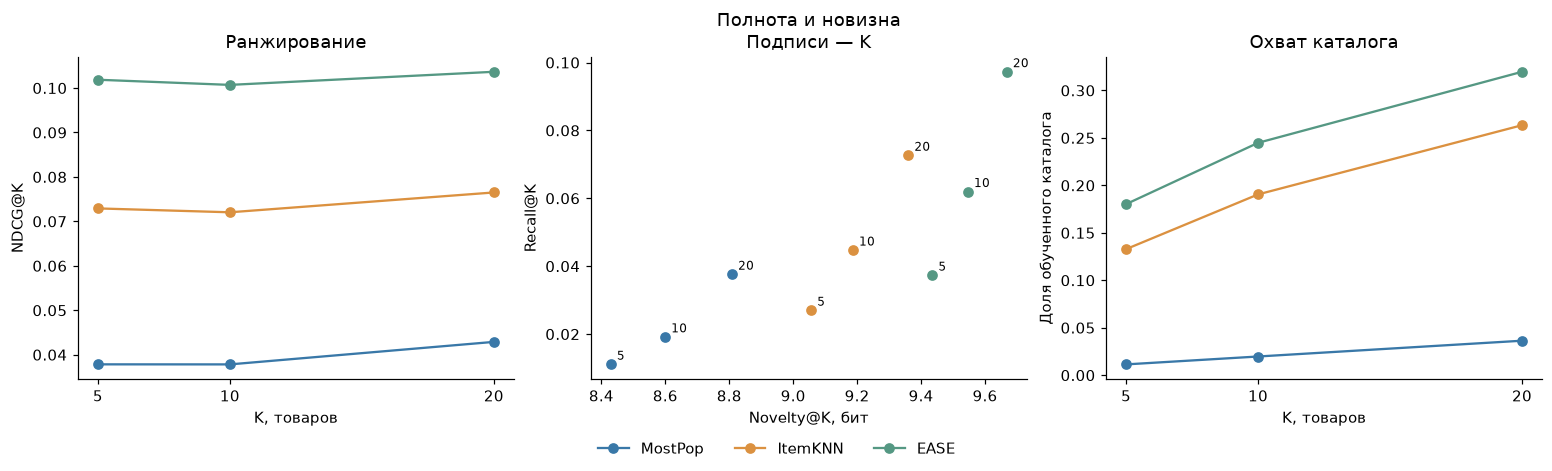

In [10]:
lengths=final_train.groupby('CustomerID').StockCode.nunique()
threshold=float(lengths.median())
individual['history_items']=individual.user.map(lengths)
individual['group']=np.where(individual.history_items<=threshold,'Короткая','Длинная')
groups=individual.query('K==10').groupby(['method','group']).agg(users=('user','size'),history_median=('history_items','median'),
                Precision=('Precision','mean'),Recall=('Recall','mean'),NDCG=('NDCG','mean'),Novelty=('Novelty','mean')).reset_index()
print('Граница короткой истории:',threshold)
display(save_table(groups,'history_groups').round(5))
pivot=individual.query('K==10').pivot(index='user',columns='method',values='NDCG')
rng=np.random.default_rng(SEED); intervals=[]
for method in ['ItemKNN','EASE']:
    delta=(pivot[method]-pivot.MostPop).to_numpy()
    means=np.array([rng.choice(delta,size=len(delta),replace=True).mean() for _ in range(2000)])
    intervals.append({'method':method,'delta':delta.mean(),'low':np.quantile(means,.025),'high':np.quantile(means,.975),
                      'better_users':int((delta>0).sum()),'worse_users':int((delta<0).sum()),'equal_users':int((delta==0).sum())})
bootstrap=save_table(pd.DataFrame(intervals),'paired_bootstrap')
display(bootstrap.round(5))
fig,axes=plt.subplots(1,3,figsize=(14,4.2),layout='constrained')
for method,color in zip(['MostPop','ItemKNN','EASE'],[BLUE,ORANGE,GREEN]):
    g=metrics[metrics.method==method]
    axes[0].plot(g.K,g.NDCG,'o-',color=color,label=method)
    axes[1].scatter(g.Novelty,g.Recall,color=color,label=method)
    for row in g.itertuples():axes[1].annotate(str(row.K),(row.Novelty,row.Recall),xytext=(4,3),textcoords='offset points',fontsize=8)
    axes[2].plot(g.K,g.Coverage,'o-',color=color,label=method)
axes[0].set(xlabel='K, товаров',ylabel='NDCG@K',title='Ранжирование',xticks=[5,10,20])
fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=3,frameon=False)
axes[1].set(xlabel='Novelty@K, бит',ylabel='Recall@K',title='Полнота и новизна\nПодписи — K')
axes[2].set(xlabel='K, товаров',ylabel='Доля обученного каталога',title='Охват каталога',xticks=[5,10,20])
fig.savefig(FIGURES/'test_comparison.png',dpi=160,bbox_inches='tight');plt.show()

В основной оценке учитываю будущие покупки только из обученного каталога. Дополнительно оставляю в релевантности и новые товары, которые модели пока не могут рекомендовать. Так проверяю, насколько ограничение каталога повлияло на результат. При этом группа покупателей может расшириться, поэтому две оценки не полностью совпадают по составу.

Новых покупателей оцениваю отдельно. Все методы возвращают им MostPop, поскольку персональной истории ещё нет.

In [11]:
sensitivity=[]
for method,model in models.items():
    agg,_,_,_=evaluate(model,test_all_truth,ks=(10,))
    sensitivity.append({'population':'Все новые товары, известные пользователи','method':method,**agg.iloc[0].to_dict()})
if cold_truth:
    agg,_,_,_=evaluate(models['MostPop'],cold_truth,ks=(10,))
    sensitivity.append({'population':'Новые пользователи, доступные товары','method':'Общий MostPop fallback',**agg.iloc[0].to_dict()})
sensitivity=save_table(pd.DataFrame(sensitivity),'cold_start_and_catalog')
display(sensitivity[['population','method','users','Precision','Recall','NDCG','Novelty','Coverage']].round(5))

,population,method,users,Precision,Recall,NDCG,Novelty,Coverage
0,"Все новые товары, известные пользователи",MostPop,1449.0,0.03430,0.01871,0.03752,8.59948,0.01968
1,"Все новые товары, известные пользователи",ItemKNN,1449.0,0.05942,0.04401,0.07153,9.18688,0.19129
2,"Все новые товары, известные пользователи",EASE,1449.0,0.08144,0.06097,0.09994,9.54648,0.24536
3,"Новые пользователи, доступные товары",Общий MostPop fallback,364.0,0.05852,0.03106,0.06824,8.51467,0.00277


### Интерпретация тестового сравнения

Лучший результат получил у EASE: NDCG@10 составил около 0,101 против 0,072 у ItemKNN и 0,038 у MostPop. Персонализация улучшила ранжирование, но абсолютное качество осталось скромным. В десятке EASE в среднем нашёл около 0,82 будущей покупки, а средняя полнота составила примерно 6,2%.

EASE также предложил менее популярные товары и охватил около четверти каталога. MostPop использовал лишь около 2%. В этом сравнении качество и новизна выросли одновременно. Компромисс между ними увидел при настройке регуляризации на validation, но не между финальными моделями.

При увеличении списка с 5 до 20 товаров получил больше попаданий и более широкий охват, но меньшую долю попаданий на одну позицию. NDCG менялся немонотонно, поскольку при смене K меняется и идеальный список для нормировки. Порядок методов сохранился при всех трёх размерах выдачи.

Преимущество персонализации сохранилось и для коротких, и для длинных историй. У длинных историй полнота оказалась ниже. Это может быть связано с большим числом будущих покупок, а не только с качеством модели. Размеры групп и их метрики привёл в таблице.

Оба bootstrap-интервала разности с MostPop оказались выше нуля. Это поддержало вывод о среднем выигрыше при выбранном временном окне, но не для каждого покупателя. Например, у 189 покупателей EASE уступил MostPop.

Учёт новых товаров вне каталога немного снизил качество, но не изменил порядок методов. Для новых покупателей проверил общий MostPop. Его результат не сравнивал напрямую с известными покупателями как эффект холодного старта, поскольку это разные группы.

Время обучения и выдачи привёл отдельно в таблице. На доступной машине EASE оказался выполнимым, но бюджет памяти для плотных вычислений оценил примерно в 500 МиБ. При существенно большем каталоге такой способ решения уже не подойдёт.

## 8. Примеры рекомендаций и ошибки

Основные примеры выбираю по длине истории, без учёта попаданий. Сортирую покупателей по числу товаров, затем по ID и беру позиции 10%, 50% и 90%. Для каждого показываю последние пять разных товаров истории и десятку рекомендаций всех методов. Названия беру только из обучающей части, попадания отмечаю по test.

Отдельно разбираю максимальный выигрыш и проигрыш EASE относительно MostPop по NDCG@10. При равенстве выбираю меньший ID. Эти крайние случаи помогают понять ошибки, но не представляют среднее качество. Для холодного старта показываю первого нового покупателя по ID. Оценки разных методов не сравниваю как вероятности.

In [12]:
names=(final_train.dropna(subset=['Description']).drop_duplicates('StockCode',keep='last')
       .set_index('StockCode').Description.to_dict())
assert set(names)<=set(final_train.StockCode)
save_table(pd.DataFrame(sorted(names.items()),columns=['item','description']),'train_item_names')
ordered=sorted(test_truth,key=lambda u:(lengths[u],u))
example_ids=[ordered[int(q*(len(ordered)-1))] for q in [.1,.5,.9]]
example_roles={u:label for u,label in zip(example_ids,['10% длины истории','50% длины истории','90% длины истории'])}
delta=pivot.EASE-pivot.MostPop
example_roles.setdefault(int(delta.idxmax()),'Максимальное преимущество EASE')
example_roles.setdefault(int(delta.idxmin()),'Максимальная потеря EASE')
example_stats=[]
for u,role in example_roles.items():
    display(Markdown(f'**Покупатель {u}: {role}. История — {lengths[u]} товаров. Релевантных новых в каталоге — {len(test_truth[u])}.**'))
    history=(final_train[final_train.CustomerID==u].drop_duplicates('StockCode',keep='last').tail(5)
             [['InvoiceDate','StockCode','Description']])
    display(history)
    part=recommendations[(recommendations.user==u)&(recommendations['rank']<=10)].copy()
    part['description']=part['item'].map(names).fillna('[название отсутствует]')
    display(part[['method','rank','item','description','hit','score']].round({'score':4}).reset_index(drop=True))
    for method in models:
        r=part[part.method==method]
        example_stats.append({'user':u,'role':role,'history_items':int(lengths[u]),'method':method,
                              'hits10':int(r.hit.sum()),'NDCG10':float(pivot.loc[u,method]),
                              'top_names':r.description.head(3).tolist()})
example_stats_path=DATA/'example_analysis.json'
example_stats_path.write_text(json.dumps(example_stats,ensure_ascii=False,indent=2))
if cold_truth:
    u=min(cold_truth)
    print('Новый покупатель:',u,'| истории нет. Релевантных доступных товаров:',len(cold_truth[u]))
    cold_rec=models['MostPop'].recommend(u,10)
    cold_example=pd.DataFrame([{'item':i,'description':names.get(i,'[нет названия]'),'score':s,'hit':i in cold_truth[u]} for i,s in cold_rec])
    display(save_table(cold_example,'cold_user_example'))
_ = save_table(recommendations[recommendations.user.isin(example_roles)],'example_recommendations')

**Покупатель 14284: 10% длины истории. История — 13 товаров. Релевантных новых в каталоге — 11.**

,InvoiceDate,StockCode,Description
238811,2011-09-14 13:04:00,23153,ZINC SWEETHEART WIRE LETTER RACK
238812,2011-09-14 13:04:00,23245,SET OF 3 REGENCY CAKE TINS
238813,2011-09-14 13:04:00,23407,SET OF 2 TRAYS HOME SWEET HOME
238814,2011-09-14 13:04:00,23423,PANTRY 3 HOOK ROLLING PIN HANGER
238815,2011-09-14 13:04:00,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS


,method,rank,item,description,hit,score
0,MostPop,1,22423,REGENCY CAKESTAND 3 TIER,False,806.0000
1,MostPop,2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,False,779.0000
2,MostPop,3,47566,PARTY BUNTING,False,685.0000
3,MostPop,4,84879,ASSORTED COLOUR BIRD ORNAMENT,False,594.0000
4,MostPop,5,22720,SET OF 3 CAKE TINS PANTRY DESIGN,False,592.0000
5,MostPop,6,21212,PACK OF 72 RETROSPOT CAKE CASES,False,587.0000
6,MostPop,7,85099B,JUMBO BAG RED RETROSPOT,False,567.0000
7,MostPop,8,23298,SPOTTY BUNTING,False,532.0000
8,MostPop,9,22457,NATURAL SLATE HEART CHALKBOARD,False,525.0000
9,MostPop,10,22469,HEART OF WICKER SMALL,False,502.0000


**Покупатель 17109: 50% длины истории. История — 56 товаров. Релевантных новых в каталоге — 51.**

,InvoiceDate,StockCode,Description
302165,2011-10-26 13:31:00,21787,RAIN PONCHO RETROSPOT
302166,2011-10-26 13:31:00,22098,BOUDOIR SQUARE TISSUE BOX
302167,2011-10-26 13:31:00,22115,METAL SIGN EMPIRE TEA
302168,2011-10-26 13:31:00,22720,SET OF 3 CAKE TINS PANTRY DESIGN
302169,2011-10-26 13:31:00,22866,HAND WARMER SCOTTY DOG DESIGN


,method,rank,item,description,hit,score
0,MostPop,1,22423,REGENCY CAKESTAND 3 TIER,False,806.0000
1,MostPop,2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,False,779.0000
2,MostPop,3,21212,PACK OF 72 RETROSPOT CAKE CASES,False,587.0000
3,MostPop,4,85099B,JUMBO BAG RED RETROSPOT,False,567.0000
4,MostPop,5,23298,SPOTTY BUNTING,True,532.0000
5,MostPop,6,22960,JAM MAKING SET WITH JARS,False,531.0000
6,MostPop,7,22457,NATURAL SLATE HEART CHALKBOARD,False,525.0000
7,MostPop,8,22469,HEART OF WICKER SMALL,False,502.0000
8,MostPop,9,20725,LUNCH BAG RED RETROSPOT,False,501.0000
9,MostPop,10,22961,JAM MAKING SET PRINTED,False,501.0000


... (7 outputs left out)

,InvoiceDate,StockCode,Description
186706,2011-07-20 13:21:00,85099F,JUMBO BAG STRAWBERRY
272089,2011-10-06 16:28:00,20914,SET/5 RED RETROSPOT LID GLASS BOWLS
272090,2011-10-06 16:28:00,22423,REGENCY CAKESTAND 3 TIER
272091,2011-10-06 16:28:00,23332,IVORY WICKER HEART LARGE
272092,2011-10-06 16:28:00,23407,SET OF 2 TRAYS HOME SWEET HOME


,method,rank,item,description,hit,score
0,MostPop,1,84879,ASSORTED COLOUR BIRD ORNAMENT,False,594.0000
1,MostPop,2,22720,SET OF 3 CAKE TINS PANTRY DESIGN,False,592.0000
2,MostPop,3,85099B,JUMBO BAG RED RETROSPOT,True,567.0000
3,MostPop,4,23298,SPOTTY BUNTING,False,532.0000
4,MostPop,5,22960,JAM MAKING SET WITH JARS,False,531.0000
5,MostPop,6,20725,LUNCH BAG RED RETROSPOT,False,501.0000
6,MostPop,7,22961,JAM MAKING SET PRINTED,False,501.0000
7,MostPop,8,22138,BAKING SET 9 PIECE RETROSPOT,False,468.0000
8,MostPop,9,20728,LUNCH BAG CARS BLUE,False,447.0000
9,MostPop,10,22086,PAPER CHAIN KIT 50'S CHRISTMAS,False,443.0000


Новый покупатель: 12349 | истории нет. Релевантных доступных товаров: 72


,item,description,score,hit
0,22423,REGENCY CAKESTAND 3 TIER,806.0,True
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,779.0,False
2,47566,PARTY BUNTING,685.0,False
3,84879,ASSORTED COLOUR BIRD ORNAMENT,594.0,False
4,22720,SET OF 3 CAKE TINS PANTRY DESIGN,592.0,True
5,21212,PACK OF 72 RETROSPOT CAKE CASES,587.0,False
6,85099B,JUMBO BAG RED RETROSPOT,567.0,False
7,23298,SPOTTY BUNTING,532.0,False
8,22960,JAM MAKING SET WITH JARS,531.0,True
9,22457,NATURAL SLATE HEART CHALKBOARD,525.0,False


### Что показали примеры

У покупателя **14284** с короткой историей EASE нашёл два товара в десятке, а MostPop и ItemKNN не дали попаданий. Среди прошлых покупок увидел кухонные товары и рождественское украшение. В рекомендациях EASE тоже появились товары для кухни и праздника.

Для **17109** все методы нашли один и тот же SPOTTY BUNTING. MostPop поставил его пятым, ItemKNN — третьим, EASE — первым. Количество попаданий совпало, но EASE получил более высокий NDCG благодаря порядку. У **17625** все методы дали ноль попаданий, несмотря на длинную историю.

В успешном крайнем случае **13323** история состояла из пяти грелок. EASE поставил будущую покупку SCOTTIE DOG HOT WATER BOTTLE первой, ItemKNN — второй, а MostPop её не нашёл. Здесь попадание совпало с понятной связью по названиям товаров.

В неудачном случае **13549** MostPop нашёл будущую сумку JUMBO BAG RED RETROSPOT, а EASE предпочёл предметы для дома и не включил её в десятку. Возможно, смешанная история оттеснила нужный товар. По одному примеру эту причину подтвердить нельзя.

Новому покупателю **12349** все методы вернули одинаковую популярную выдачу. Она дала три попадания, но персонализации без истории здесь не было.

## 9. Итоговые выводы

Реализовал и проверил MostPop, ItemKNN и EASE. На выбранном временном разбиении лучший NDCG@10 получил у **EASE с λ=1000** — около 0,101. Он также дал более новые рекомендации и охватил большую часть каталога. ItemKNN тоже превзошёл MostPop.

При этом качество осталось ограниченным. Даже EASE в среднем нашёл меньше одной будущей покупки в десятке, а у части покупателей уступил популярности. Для новых пользователей персонализация не работала, поэтому использовал MostPop. Вывод относится к новым товарам для покупателя в одном магазине и одном сезонном окне.